In [1]:
# Idea: 3 Images with detections and lines that indicate label propagation over objects

In [2]:
import matplotlib.pyplot as plt 

In [3]:
coco_root = "/home/klees/data/coco/val2017/"

In [4]:
# img1 = coco_root + "000000002149.jpg" # apples in a bowl


# img2 = coco_root + "000000012667.jpg" # bananas


# img3 = coco_root + "000000044669.jpg" # bananas and apples


# giraffes and zebras:

img1 = coco_root + "000000064359.jpg" # giraffes & zebras -> Annotations here

# img2 = coco_root + "000000054123.jpg" # zebras
img2 = coco_root + "000000052462.jpg" # two zebras

# img3 = coco_root + "000000033707.jpg" # two giraffes
# img3 = coco_root + "000000079188.jpg" # two giraffes
img3 = coco_root + "000000157098.jpg" # three giraffes

In [5]:
import cv2
import numpy as np

# img1 (giraffes & zebras) and img3 (three giraffes) were shot in heavy
# shade and come out noticeably darker/flatter than img2 (two zebras in
# bright grass) -> brighten those two before plotting, leave img2 as-is.
def enhance_lighting(rgb, gamma=0.85, clip_limit=2.0, tile_grid_size=(8, 8)):
    """Brighten and recover local contrast in an underexposed photo.

    CLAHE (on the LAB lightness channel) pulls detail out of the shadows
    without blowing out the already-bright areas; the gamma lift on top
    corrects the overall underexposure. Gamma < 1 brightens. Takes/returns
    a uint8 RGB array (i.e. plugs directly into plt.imread / ax.imshow).
    """
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l = clahe.apply(l)
    rgb = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
    lut = ((np.arange(256) / 255.0) ** gamma * 255.0).astype(np.uint8)
    return cv2.LUT(rgb, lut)

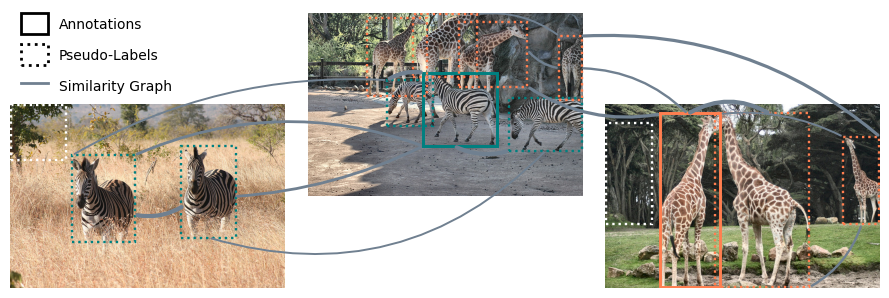

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(9,4))

# image locations
images = [
    (3.25, 0.5, 3, 2), # middle slightly above the other two
    (0, -0.5, 3, 2),
    (6.5, -0.5, 3, 2),
]

# draw images
img_paths = [img1, img2, img3]
brighten = [True, False, True]  # img1 & img3 are dark; img2 (two zebras) is fine as-is
for i, (x, y, w, h) in enumerate(images):
    arr = plt.imread(img_paths[i])
    if brighten[i]:
        arr = enhance_lighting(arr)
    ax.imshow(arr, extent=(x, x+w, y, y+h))

# bounding boxes
boxes = {
    "zebra_prop_1": (0.68, 0.0, 0.68, 0.95),
    "zebra_prop_2": (1.87, 0.05, 0.6, 1.0),

    "zebra_gt_1": (4.515, 1.05, 0.8, 0.8),
    "giraffe_gt_1": (7.1, -0.49, 0.65, 1.9),

    "zebra_prop_3": (4.12, 1.27, 0.5, 0.5),
    "zebra_prop_4": (5.45, 1.0, 0.8, 0.58),

    # right image
    "giraffe_prop_1": (7.7, -0.49, 1.03, 1.9),

    "giraffe_prop_2": (9.1, 0.2, 0.39, 0.95),

    "giraffe_prop_3": (6.0, 1.55, 0.25, 0.7),
    "giraffe_prop_4": (4.9, 1.7, 0.75, 0.7),
    "giraffe_prop_5": (4.4, 1.8, 0.7, 0.69),
    "giraffe_prop_6": (3.9, 1.6, 0.65, 0.85),

    # FP detections
    "FP_1": (0.01, 0.9, 0.6, 0.6),
    "FP_2": (6.51, 0.2, 0.5, 1.1),
}

bbox_lw = 1.7
labeled_factor = 1.25 # increase line width for GT boxes
# propagated zebra labels
for key in ["zebra_prop_1", "zebra_prop_2", "zebra_prop_3", "zebra_prop_4"]:
    x,y,w,h = boxes[key]
    ax.add_patch(
        Rectangle((x,y),w,h,
                  fill=False,
                  edgecolor="teal",
                  linestyle="dotted",
                  linewidth=bbox_lw)
    )

# zebra annotation
for key in ["zebra_gt_1"]:
    x,y,w,h = boxes[key]
    ax.add_patch(
        Rectangle((x,y),w,h,
                  fill=False,
                  edgecolor="teal",
                  linestyle="solid",
                  linewidth=bbox_lw*labeled_factor)
    )

# giraffe annotation
for key in ["giraffe_gt_1"]:
    x,y,w,h = boxes[key]
    ax.add_patch(
        Rectangle((x,y),w,h,
                  fill=False,
                  edgecolor="coral",
                  linestyle="solid",
                  linewidth=bbox_lw*labeled_factor)
    )


# propagated giraffe labels
for key in ["giraffe_prop_1", "giraffe_prop_2", "giraffe_prop_3", "giraffe_prop_4", "giraffe_prop_5", "giraffe_prop_6"]:
    x,y,w,h = boxes[key]
    ax.add_patch(
        Rectangle((x,y),w,h,
                  fill=False,
                  edgecolor="coral",
                  linestyle="dotted",
                  linewidth=bbox_lw)
    )

# FP detections
for key in ["FP_1", "FP_2"]:
    x,y,w,h = boxes[key]
    ax.add_patch(
        Rectangle((x,y),w,h,
                  fill=False,
                  edgecolor="white",
                  linestyle="dotted",
                  linewidth=bbox_lw)
    )

# arrows
arrows = [
    # labeled zebra to left image 
    ((1.36,0.95),(4.51,1.05), 2, -0.2),
    ((1.36,0.3),(1.9,0.4), 3, 0.2),
    # left image only
    ((2.45,0.5),(4.51,1.05), 2, 0.1),

    # labeled zebra to middle image
    ((4.85,1.05),(5.45,1.0), 3, 0.2),
    ((4.515,1.85),(4.12,1.77), 3, 0.2),
    # middle image only -> leave out for readability

    # unlabeled zebras
    ((0.68,0.95),(4.12,1.77), 1.4, -0.15),
    ((2.17,0.05),(5.85,1.0), 1.4, 0.3),


    #  giraffes

    # right image
    ((7.4,1.4),(8.3,1.4), 3, -0.3),
    ((7.75,1.4),(9.1,1.15), 1.4, -0.15),
    ((8.73,-0.49),(9.3,0.2), 1.7, 0.2),

    # cross image propagation

    ((7.4,1.4),(6.23,1.9), 1.7, 0.2),
    ((6.23,2.25),(9.5,1.15), 2.3, -0.2),
    ((5.65,1.7),(7.1,1.4), 2.3, 0.2),
    ((5.65,2.1),(6.0,1.9), 1.7, 0.2),
    ((5.1,2.49),(6.0,2.25), 1.4, -0.2),
    

]

for start,end,lw,rad in arrows:
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-",
            connectionstyle='arc3,rad={}'.format(rad),
            linewidth=lw,
            linestyle="solid",
            color = "slategray"
        )
    )

# ax.text(0.4,-0.35,"Ground Truth",color="green",fontsize=12)
# ax.text(4.4,-0.35,"Propagated Labels",color="royalblue",fontsize=12)

ax.set_xlim(0,9.5)
ax.set_ylim(-0.5,2.5)
ax.axis("off")

# add legend

from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

legend_handles = [
    Rectangle(
        (0, 0), 1, 1,
        fill=False,
        edgecolor= 'black',
        linewidth=2,
        linestyle='-',
        label='Annotations'
    ),
    Rectangle(
        (0, 0), 1, 1,
        fill=False,
        edgecolor= 'black',
        linewidth=2,
        linestyle='dotted',
        label='Pseudo-Labels'
    ),
    Line2D(
        [0], [0],
        color='slategray',
        linewidth=2,
        linestyle='-',
        label='Similarity Graph'
    )
]

ax.legend(
    handles=legend_handles,
    loc='upper left',
    bbox_to_anchor=(0.0, 1.04),
    frameon=False,
    handlelength=1.9,
    handleheight=1.9,
    borderpad=0.3,
    labelspacing=0.75,
)

plt.tight_layout()

plt.savefig("abstract_figure.png", bbox_inches="tight", dpi=300)
plt.savefig("abstract_figure.pdf", bbox_inches="tight", dpi=300)
plt.show()